In [117]:
words = open('names.txt', 'r').read().splitlines()

In [110]:
import torch 
N = torch.zeros((27,27), dtype=torch.int32)
# Indexing and overwriting  is support using [row, column] 0-indexed 

In [116]:
# Gets a list of all characters + '.', creates a string to int / int to string dictionary
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i,s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}

In [119]:
# In order to learn the statistics of which character follows a char, the simplest way is to count how often a combination of two char occurs. 
# Use a pytorch matrix to map first char (first column) to second char (first row)
for w in words:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        N[ix1, ix2] +=1

In [120]:
import matplotlib.pyplot as plt
%matplotlib inline 

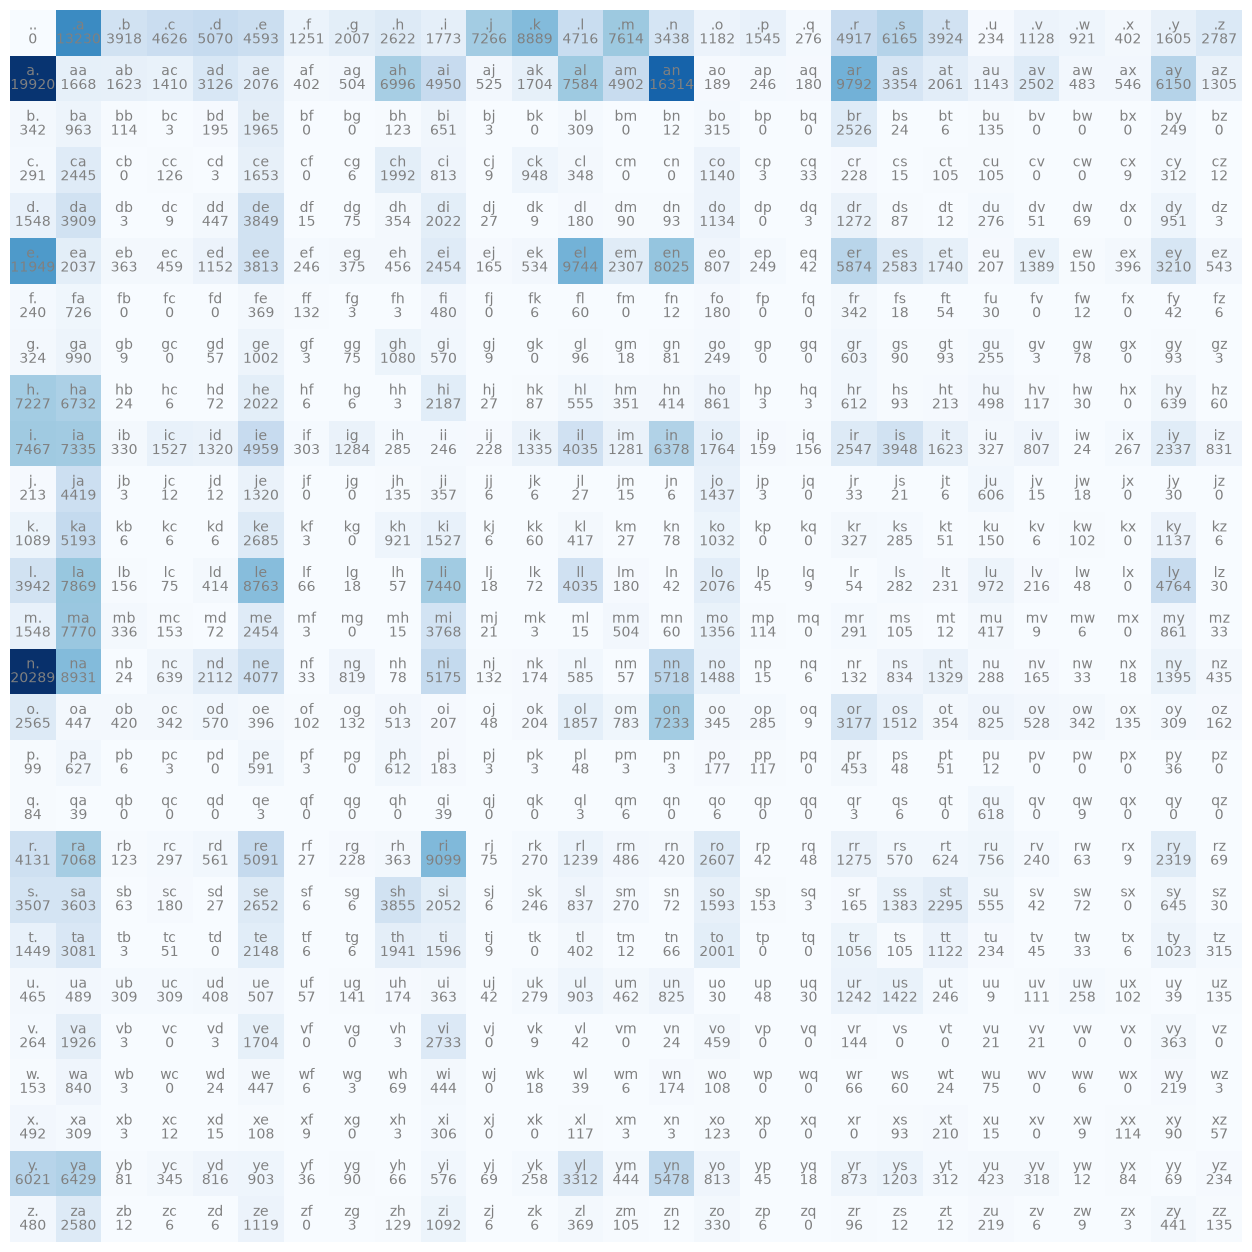

In [121]:
# Generate frequency table 
plt.figure(figsize=(16,16))
plt.imshow(N, cmap='Blues')
for i in range(27):
    for j in range(27):
        chstr = itos[i] + itos[j]
        plt.text(j, i, chstr, ha="center", va="bottom", color='gray')
        plt.text(j,i, N[i,j].item(), ha="center", va="top", color="gray")
plt.axis("off");

In [134]:
## The Algorithm for selecting the most probable character, based on g [random number] 

p = N[0].float() # arbitrary numbers in a list
p = p / p.sum() # normalization creates pd
p #probability distribution 

g = torch.Generator().manual_seed(2147483647) # this just makes the random sampling reproduceable 
ix1 = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item() # randomly samples an index according to those probabilities
itos[ix1] # character assigned to the index that owns a cumulative interval 

tensor([0.0000, 0.1377, 0.0408, 0.0481, 0.0528, 0.0478, 0.0130, 0.0209, 0.0273,
        0.0184, 0.0756, 0.0925, 0.0491, 0.0792, 0.0358, 0.0123, 0.0161, 0.0029,
        0.0512, 0.0642, 0.0408, 0.0024, 0.0117, 0.0096, 0.0042, 0.0167, 0.0290])

In [140]:
"""
### -------- NOTES ON MULTINOMIAL ---------------------
Essentially, multinomial takes in two major parameters: p and g 
p is the list of probability distribution (random probabilities assigned an index)
g is a random  number generator from 0 - 1

under the hood, each probability distribution is summed to create a cumulative sequence wherein the sequence intervals are the
result of the probability being added. now g will give a number between 0 and 1, and the cumulative sequence determines which 
index owns that region of interval. 

for example if p = [ 0.4, 0.3, 0.2, 0.1 ] 
and if g = 0.85
the cumulative sequence is 0 -> 0.4 -> 0.7 -> 0.9 -> 1 
according to the sequence 0.85 rest between 0.7 -> 0.9
p[2] is responsible for that interval = 0.2
the output now will be the index that 0.2 owns, which here is 2 
therefore the output of the multinomial where p and g are parameters, and g produces 0.85 is 2
2 can be indexed to a character, and this in turn generates random characters under the basis of probability distribution and random g

"""

##### --- NOTES ON BROADCASTING SEMANTICS 

# Now broadcasting a [27, 27] / [27, 1] - it is broadcastable
# Broadcasting semantics: checks to see if two tensors can be combined in a binary operation 
# binary rules says: the dimension sizes must either be equal, one of them is 1, or one of them does not exist
# Internally, if the dims does not exist, it will align from the trailing end (right), then iterate if its same, 1, or DNE (where it makes a 1)
# Internally, if the dims are 27 and 1, the 1 column is being stretched out 27x and then it does an element wise divison 


'c'

In [196]:
# Broadcasting Semantics + Keepdims responsibility 
# Added +1 to every probability prevents loss from -inf
g = torch.Generator().manual_seed(2147483647) 

P = (N+1).float()
P /= P.sum(1, keepdims=True) # [27, 1] -> [27, 27] 

In [197]:
### SAMPLE 1: BIGRAM MODEL BASED ON FREQUENCY TABLE --------------------------------------

for i in range(10):
    out = []
    ix = 0
    while True: 
        p = P[ix] 
        ix = torch.multinomial(p, num_samples=1, replacement=True, generator=g).item()
        out.append(itos[ix])
        if ix == 0:
            break 
    print(''.join(out))


cexze.
momasurailezitynn.
konimittain.
llayn.
ka.
da.
staiyaubrtthrigotai.
moliellavo.
ke.
teda.


In [198]:
# GOAL: Maximize likelihood of the data w.r.t the model parameters (statistical modeling)
# The idea is: a good model means the product of the log-probabilities is as high as possible
# taking the product of many log probabilites is the same as its sum log(a*b*c) = log(a) + log(b) + log(c) 
# Log Likelihood measures how well of a probability did the model assign to the bigram training tokens 
# In theory, by taking the negative log_likelihood and averaging it (over all the names), gives a loss variable 


log_likelihood = 0.0
n = 0 
for w in ["hakeemq"]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]

        prob = P[ix1, ix2] # fetch probability of bigram 
        logprob = torch.log(prob) # apply a monotomic transformation (smoothen it out) 

        log_likelihood += logprob 
        n += 1
        print(f"{ch1}{ch2}: {prob:.4f} {logprob}") 

print(f"{log_likelihood=}")
nll = -log_likelihood 
print(f"{nll=}")
print(f"{nll/n:.4f}")

# if a character is followed by a character which according to our parameters (statistical modeling) has a 0% probability, the loss is infinite. 
# to smooth this out, add a 1 or (higher #) offset to each probability to smoothen it out. 

.h: 0.0273 -3.6013410091400146
ha: 0.2943 -1.223023772239685
ak: 0.0168 -4.088284969329834
ke: 0.1773 -1.7297494411468506
ee: 0.0622 -2.777036190032959
em: 0.0377 -3.2793333530426025
mq: 0.0001 -9.901134490966797
q.: 0.1008 -2.294315814971924
log_likelihood=tensor(-28.8942)
nll=tensor(28.8942)
3.6118


In [219]:
"""
PART 2: CREATING A NEURAL NETWORK THAT PREDICTS THE NEXT CHARACTER 
"""

# STEP 1: CREATE THE TRAINING SET OF BIGRAM - two tensor list
xs, ys = [], []
for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]): 
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        print(f"{ch1}{ch2}")
        xs.append(ix1)3
        ys.append(ix2)

.e
em
mm
ma
a.


In [220]:
# STEP 2: Feeding integers into neural networks: one-hot encoding (encode the integer into a sparse vector where itos is 1)
import torch.nn.functional as F
xenc = F.one_hot(xs, num_classes=27).float() # num_classes = # of zeros | change dtype from int32 to float32 better for NN 
xenc 

tensor([[1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 1., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.],
        [0., 1., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0., 0.,
         0., 0., 0., 0., 0., 0., 0., 0., 0.]])

In [222]:
# STEP 3: Implement weights for inputs 
W = torch.randn((27,27)) # normal distribution 27,1 Matrix 
xenc @ W # (5, 27) @ (27, 27) Binary opeartion that removes 27s, left with (5,27) matrix of random nums  

# think of xenc as your batch of inputs 
# think of W as your neurons (columns) with weights (rows)
# you multiply them as per the forward pass of the neural network 

tensor([[-0.4835, -0.1953, -0.0996, -0.3215, -0.3776,  0.0644, -0.4951, -1.6150,
          2.0611,  0.6589, -0.0527,  0.6710,  0.4509, -0.4638,  1.0853, -0.6137,
          0.3628, -1.0321,  0.3493, -1.2155,  1.5062, -0.7724,  0.5721, -0.6724,
          0.7597, -0.7420, -1.3788],
        [ 1.4286,  0.7166, -0.9789,  0.2232, -0.7798,  0.1528, -0.3916, -0.5940,
          0.3950, -0.2637, -0.3253, -0.2279, -0.6461,  1.2532,  0.9366,  0.6555,
          0.8327,  1.7846,  1.3332,  2.6066, -0.6035, -1.1199,  1.5985, -0.7650,
         -0.7005, -0.5758, -1.0524],
        [-0.1834, -1.5175, -1.2674,  0.9436,  0.5534, -0.2307,  0.6957, -2.1835,
          0.7792, -0.7068,  0.2840,  0.9614, -0.8797, -1.1346, -0.6330, -2.1488,
         -0.9497, -0.8631,  0.4372, -0.2294, -1.1698, -1.1936, -0.2174,  0.4570,
          0.9636,  0.7372, -1.8977],
        [-0.1834, -1.5175, -1.2674,  0.9436,  0.5534, -0.2307,  0.6957, -2.1835,
          0.7792, -0.7068,  0.2840,  0.9614, -0.8797, -1.1346, -0.6330, -2.1488

In [227]:
# STEP 4: TURNING EACH NEURON SORE (LOG-COUNTS) AND EXPONENTIATING THEM SO THEY CAN BE NORMALIZED AND BECOME PROBABILITIES
logits = (xenc @ W) # log counts (logprob)
counts = logits.exp() # smooth
probs = counts / counts.sum(1, keepdims=True)

probs[0].sum() #proof

tensor(1.0000)

In [243]:
# STEP 4.5: Summary For Me
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27,27), generator=g)

xenc = F.one_hot(xs, num_classes=27).float()
logits = xenc @ W 
counts = logits.exp()
prob = counts / counts.sum(1, keepdims=True)

# the last two lines are called the softmax activation function 

In [245]:
nlls = torch.zeros(5)
for i in range(5):
    x = xs[i].item()
    y = ys[i].item() 
    print(f"Example {i+1}: {itos[x]} {itos[y]}")
    print(f"Input to the neural net: {x}")
    print(f"output probability:", probs[i])
    print("label for the actual character:", y)
    p = probs[i,y]
    print("Probability assigned by the net to the correct character: ", p.item()) 
    logp = torch.log(p)
    print("log-likelihood: ", logp.item())
    nll = -logp
    print("Negative log-likelihood:", nll.item())
    nlls[i] = nll

print("--------------")
print("Average negative log likelihood: loss=", nlls.mean().item())

Example 1: . e
Input to the neural net: 0
output probability: tensor([0.0164, 0.0218, 0.0240, 0.0193, 0.0182, 0.0283, 0.0162, 0.0053, 0.2086,
        0.0513, 0.0252, 0.0520, 0.0417, 0.0167, 0.0786, 0.0144, 0.0382, 0.0095,
        0.0377, 0.0079, 0.1198, 0.0123, 0.0471, 0.0136, 0.0568, 0.0126, 0.0067])
label for the actual character: 5
Probability assigned by the net to the correct character:  0.028328202664852142
log-likelihood:  -3.5638973712921143
Negative log-likelihood: 3.5638973712921143
Example 2: e m
Input to the neural net: 5
output probability: tensor([0.0742, 0.0364, 0.0067, 0.0222, 0.0081, 0.0207, 0.0120, 0.0098, 0.0264,
        0.0137, 0.0128, 0.0142, 0.0093, 0.0622, 0.0453, 0.0342, 0.0409, 0.1059,
        0.0674, 0.2409, 0.0097, 0.0058, 0.0879, 0.0083, 0.0088, 0.0100, 0.0062])
label for the actual character: 13
Probability assigned by the net to the correct character:  0.06222878769040108
log-likelihood:  -2.776937484741211
Negative log-likelihood: 2.776937484741211
Exampl

In [246]:
# STEP 5: OPTIMIZATION FOR THE NEURAL NETWORK [ ENTER LOSS ]
xs

tensor([ 0,  5, 13, 13,  1])

In [247]:
ys

tensor([ 5, 13, 13,  1,  0])

In [297]:
# randomly generate weights for each neuron
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

In [312]:
# forward pass 
xenc = F.one_hot(xs, num_classes=27).float()
logits = xenc @ W 
counts = logits.exp()
probs = counts / counts.sum(1, keepdims=True)
loss = -probs[torch.arange(5), ys].log().mean() # Defined the forward pass all the way to loss 

In [320]:
probs[torch.arange(5), ys]

tensor([9.9864e-01, 9.9866e-01, 3.5027e-04, 9.9959e-01, 9.9861e-01],
       grad_fn=<IndexBackward0>)

In [306]:
print(loss.item())

3.7492127418518066


In [302]:
# Backward Pass time 
W.grad = None # set to zero gradient 
loss.backward()

In [303]:
# update 
W.data += -0.1 * W.grad

In [321]:
## FULLY FLEDGE 5 STEP GRAIDENT DESCENT _-------------------------------------------------

# ---------- !!! OPTIMIZATION !!! yay, but this time actually -------------

# create the dataset
xs, ys = [], []
for w in words[:1]:
    chs = ['.'] + list(w) + ['.']
    for ch1, ch2 in zip(chs, chs[1:]):
        ix1 = stoi[ch1]
        ix2 = stoi[ch2]
        xs.append(ix1)
        ys.append(ix2)

xs = torch.tensor(xs)
ys = torch.tensor(ys)
num = xs.nelement()
print('number of examples: ', num)
# initialize the 'network'
g = torch.Generator().manual_seed(2147483647)
W = torch.randn((27, 27), generator=g, requires_grad=True)

number of examples:  5


In [327]:
# gradient descent
for k in range(100):

    # forward pass
    xenc = F.one_hot(xs, num_classes=27).float()  # input to the network: one-hot encoding
    logits = xenc @ W  # predict log-counts
    counts = logits.exp()  # counts, equivalent to N
    probs = counts / counts.sum(1, keepdims=True)  # probabilities for next character
    loss = -probs[torch.arange(num), ys].log().mean() + 0.01*(W**2).mean()
    print(loss.item(), "Probability of training tokens: ", probs[torch.arange(5), ys])

    # backward pass
    W.grad = None  # set to zero the gradient
    loss.backward()

    # update
    W.data += -0.5 * W.grad


# AT the end of the day, this is how you create a character-level language model that improves its performence of predicting the best next token
# using MLP neural networks that pass through fine-tuning weights matrix, produces logits, smooths it, normalizes it, calculates the loss. And performs 
# gradient descent on the model to better have it predict xs[i] to ys[i] 

# Why wont the loss become 0:
# The model is given too less of cotent, the training tokens might claim that character 'a' has the same likelihood of coming after 'c' just as 'b'
# would, so both probabilities are split equally so it reaches an asymptote in its probability distribution, and wont improve further. 

# INTERESTING NOTES: 
# 1. Because the input is a sparse vector, its almost taking the row that aligns with the character index and returns that as its logit
# 2. In the gradient descent model, incentivizing W (weights) to be closer to 0 is equivalent label smoothing (uniform distribution): this 
#    is called REGULARIZATION (augment the loss function to have a small component called regularization loss)
#    the regularization component of loss is pushing W closer 0, which is equivalent to add a base number to N from the previous example

0.3243059515953064 Probability of training tokens:  tensor([0.9641, 0.9639, 0.4838, 0.4838, 0.9636], grad_fn=<IndexBackward0>)
0.3241821825504303 Probability of training tokens:  tensor([0.9642, 0.9640, 0.4839, 0.4839, 0.9637], grad_fn=<IndexBackward0>)
0.324059396982193 Probability of training tokens:  tensor([0.9644, 0.9641, 0.4839, 0.4839, 0.9638], grad_fn=<IndexBackward0>)
0.3239375650882721 Probability of training tokens:  tensor([0.9645, 0.9643, 0.4840, 0.4840, 0.9639], grad_fn=<IndexBackward0>)
0.3238164186477661 Probability of training tokens:  tensor([0.9646, 0.9644, 0.4840, 0.4840, 0.9641], grad_fn=<IndexBackward0>)
0.3236963152885437 Probability of training tokens:  tensor([0.9648, 0.9645, 0.4841, 0.4841, 0.9642], grad_fn=<IndexBackward0>)
0.3235769271850586 Probability of training tokens:  tensor([0.9649, 0.9646, 0.4841, 0.4841, 0.9643], grad_fn=<IndexBackward0>)
0.32345858216285706 Probability of training tokens:  tensor([0.9650, 0.9648, 0.4842, 0.4842, 0.9645], grad_fn=<I

In [ ]:
# PART 2 - IMPLEMENTING MLP 

# increasing the context to 2 or 3 characters which in turn exponentially grows the matrix 
